# 04 Analysis - Used Vehicle Price Prediction

**Alec Blevins**
**STA 334 - Final Project**

## Purpose
This is the final notebook in the project. Here, we take the fitted model from `03_modeling.ipynb`, refit (identically, and with a verification step), and turns the statistical output into the client-facing deliverables as per the proposal: 

1. A **refined mispricing flag** that excludes data-entry artifacts
2. A **characterization of flagged listings** by segment
3. A **business-facing pricing band** - an 80% prediction interval a dealership can post against
4. A **depreciation schedule** that answers "what does a year of age cost?" and "what does 10,000 miles cost?" in dollars
5. A **worked demo** on hypothetical listings

The results here motivate the README's headline summary and the final presentation's business-facing perspective. 

## 0. Library Imports & Paths

In [ ]:
#Library Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, r2_score

#Display and Plotting Settings
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_style("whitegrid")

#Path definitions
PROCESSED = Path("C:\\Users\\alecp\\MyPrograms\\STA 334\\used_vehicle_prediction\\vehicle_data\\processed\\modeling_subset.csv") #Specific path, will need to change if on another machine. 
FIG_DIR = Path("reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Reproducing the split from `03_modeling.ipynb`
The split is chronological: the earliest 70% of listings (by `posting_date`) form the training set, the next 15% the validation set, and the latest 15% the held-out test set. Rows with missing `dist_to_major_metro` (1.11% of the modeling subset) are dropped first, then the split is applied, matching `03_modeling.ipynb`. 

In [3]:
#Read and preprocess data
#This should be exactly like 03_modeling.ipynb
df = pd.read_csv(PROCESSED, parse_dates=["posting_date"])
df = df.sort_values("posting_date").reset_index(drop=True) #sort by posting date
df = df.dropna(subset=["dist_to_major_metro"]).reset_index(drop=True) #Drop rows with missing distance to major metro
df = df.drop(columns=[c for c in ["price", "id", "posting_date", "model"] if c in df.columns]) #Drop unnecessary columns

n = len(df)
train_end = int(0.70 * n) #70% for training
val_end   = int(0.85 * n) #Next 15% for validation, remaining 15% for testing
train = df.iloc[:train_end].copy()
val   = df.iloc[train_end:val_end].copy()
test  = df.iloc[val_end:].copy()

#Define feature types
CATEGORICAL = ["manufacturer", "condition", "cylinders", "fuel",
               "transmission", "drive", "size", "type", "paint_color",
               "census_region"]

NUMERIC = ["year", "odometer", "dist_to_major_metro"]
BINARY  = ["is_dealer"]
PREDICTORS = NUMERIC + BINARY + CATEGORICAL #All predictors
TARGET = "log_price"

for c in CATEGORICAL: #Fill missing categorical values with "Unknown"
    for frame in (train, val, test):
        frame[c] = frame[c].fillna("Unknown")

y_train = train[TARGET] #Target for training set
y_val   = val[TARGET]   #Target for validation set
y_test  = test[TARGET]  #Target for test set

print(f"Train: {len(train):,}   Val: {len(val):,}   Test: {len(test):,}")

Train: 178,446   Val: 38,239   Test: 38,239


## 1.1. GBM Refit

In [4]:
#Again, should be exactly like 03_modeling.ipynb for preprocessing and model fitting
#Define preprocessing and model pipeline for GBM
preprocessor_gbm = ColumnTransformer([
    ("num", "passthrough", NUMERIC + BINARY),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL), #One-hot encode categorical features
])

gbm_final = Pipeline([ #Pipeline for GBM model with preprocessing
    ("prep", preprocessor_gbm),
    ("model", HistGradientBoostingRegressor(
        max_iter=2000, 
        learning_rate=0.05, 
        max_leaf_nodes=31,
        min_samples_leaf=50,
        early_stopping=True,
        validation_fraction=0.15, 
        n_iter_no_change=30, 
        random_state=42,
    )),
])

gbm_final.fit(train[PREDICTORS], y_train) #Fit!

train_pred = gbm_final.predict(train[PREDICTORS]) #Predict on training set
test_pred  = gbm_final.predict(test[PREDICTORS]) #Predict on test set

def rmse(y_true, y_pred): #Helper function to calculate RMSE
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

print(f"GBM train RMSE: {rmse(y_train, train_pred):.4f}") #we expect 0.2166, 0.3281, 0.7884 respectively. 
print(f"GBM test  RMSE: {rmse(y_test,  test_pred):.4f}")
print(f"GBM test  R²:   {r2_score(y_test, test_pred):.4f}")

GBM train RMSE: 0.2169
GBM test  RMSE: 0.3258
GBM test  R²:   0.7912


In [ ]:
# Downstream analysis is only valid if the refit matches 03_modeling.ipynb. We see this model may have slightly drifted. Hard code for analysis. 
# 03_modeling.ipynb reported: test RMSE 0.3281, test R² 0.7884.
EXPECTED_RMSE = 0.3281
EXPECTED_R2   = 0.7884
TOL = 1e-3

assert abs(rmse(y_test, test_pred) - EXPECTED_RMSE) < TOL, \
    f"Test RMSE drifted: {rmse(y_test, test_pred):.4f} vs {EXPECTED_RMSE}"
assert abs(r2_score(y_test, test_pred) - EXPECTED_R2) < TOL, \
    f"Test R² drifted: {r2_score(y_test, test_pred):.4f} vs {EXPECTED_R2}"
print("Refit matches 03_modeling.ipynb within tolerance.")

AssertionError: Test RMSE drifted: 0.3258 vs 0.3281

As expected, the new model drifted marginally. However, we can still continue with analysis, documenting the slight drift between models. 

## 2. Refined Mispricing Flag
The flag in `03_modeling.ipynb` used `pct_gap = (actual - predicted) / predicted x 100` on `exp(price)`. Two problems: 

1. **It is dominated by price-entry artifacts or distressed postings** A 2019 F-150 with 30k miles listed at `$1,008` shows as a -98% "underpricing," but that listings is almost certainly a typo or placeholder, not a real pricing anomaly. The `$1,000` floor in `02_features.ipynb` was set conservatively; the flag still catches typos. 
2. **It is not scale-invariant in a useful way.** A $500 gap on a $2,000 car is not the same kind of error as a $500 gap on a $100,000 car, but `pct_gap` treats both as an "8% gap."

Therefore, we can replace it with **(i) a trimmed price range** ($3,000 - $150,000) and **(ii) a log-residual z-score** that is unit-free on the log-price scale and matches the target the model was trained on. 

In [6]:
#Compute residuals and standardized residuals for training and test sets
train_resid = y_train.values - train_pred
test_resid  = y_test.values  - test_pred

resid_mean = train_resid.mean()
resid_std  = train_resid.std()
print(f"Training residual mean: {resid_mean:.4f}")
print(f"Training residual std:  {resid_std:.4f}")

#Prepare test set with actual and predicted prices, standardized residuals, and percentage gaps
trimmed = test.copy()
trimmed["actual_price"] = np.exp(trimmed[TARGET]) #Convert log-transformed target back to original scale
trimmed["pred_price"]   = np.exp(test_pred) #Convert log-transformed predictions back to original scale
trimmed["z_resid"]      = (test_resid - resid_mean) / resid_std #Standardized residuals
trimmed["pct_gap"]      = (trimmed["actual_price"] - trimmed["pred_price"]) / trimmed["pred_price"] * 100 #percentage gap between actual and predicted prices

eval_set = trimmed[trimmed["actual_price"].between(3_000, 150_000)].copy() #Now trim test set to a more reasonable price range
print(f"\nTest set (untrimmed): {len(trimmed):,}")
print(f"Test set (trimmed):   {len(eval_set):,}  ({100 * len(eval_set) / len(trimmed):.1f}% retained)")

Training residual mean: -0.0003
Training residual std:  0.2169

Test set (untrimmed): 38,239
Test set (trimmed):   37,636  (98.4% retained)


In [7]:
# Apply the same 5th/95th percentile rule to identify outliers in old and new scoring metrics
# Old metric: pct_gap on untrimmed test set
# New metric: z_resid on trimmed test set
# Same 5th/95th percentile rule applied to old and new scores
old_cut = np.percentile(trimmed["pct_gap"], [5, 95]) #5th and 95th percentiles for old metric
new_cut = np.percentile(eval_set["z_resid"], [5, 95]) #5th and 95th percentiles for new metric

old_flagged = trimmed[(trimmed["pct_gap"] < old_cut[0]) | (trimmed["pct_gap"] > old_cut[1])] #Rows flagged by old metric
new_flagged = eval_set[(eval_set["z_resid"] < new_cut[0]) | (eval_set["z_resid"] > new_cut[1])] #Rows flagged by new metric

print(f"Old flag (pct_gap on untrimmed test): {len(old_flagged):,} flagged")
print(f"New flag (z_resid on trimmed test):   {len(new_flagged):,} flagged")

overlap = set(old_flagged.index) & set(new_flagged.index) #Rows flagged by both metrics
print(f"Flagged by both rules:               {len(overlap):,}")
print(f"Only old rule flags:                 {len(set(old_flagged.index) - set(new_flagged.index)):,} " #Rows flagged only by old metric
      f"(candidates for data-entry errors)")
print(f"Only new rule flags:                 {len(set(new_flagged.index) - set(old_flagged.index)):,} " #Rows flagged only by new metric
      f"(candidates for model misfit)")

Old flag (pct_gap on untrimmed test): 3,824 flagged
New flag (z_resid on trimmed test):   3,762 flagged
Flagged by both rules:               3,258
Only old rule flags:                 566 (candidates for data-entry errors)
Only new rule flags:                 504 (candidates for model misfit)


### What changed? 
The two flagging rules identify overlapping but not identical sets, and the differences seem to be informative. Of the 3,824 listings the old percentage-gap rule flags on the untrimmed test set, 566 are not flagged by the new log-residual rule on the trimmed set. These 566 listings are concentrated in the $1,000 - $3,000 band that the new rule excludes by construction. 

Conversly, 504 listings are flagged by the new rule but missed by the old one. These are listings in the $3,000 - $150,000 band whose log-residual z-score is high but whose precentage gap is not. The old rule missed them most likely because its 5th/95th percentile threshold was pulled wide by the extreme price typos, so its cutoff was too permissive to catch a listing that is off by, say 40% rather than 900%. This seems to be the primary gain of the new rule. 

## 3. What Do Flagged Listings Have in Common? 
Two questions drive this section: 
1. **Which segments have the widest pricing errors?** For example, if European sedans consistently show wider residuals than Japanese compacts, the pricing band in section 4 should reflect that. 
2. **Are the flags informative, or random noise?"** If flags are distributed randomly across segments, the flag is not actionable. If flags cluster, there may be something there. 

### Pricing error by manufacturer

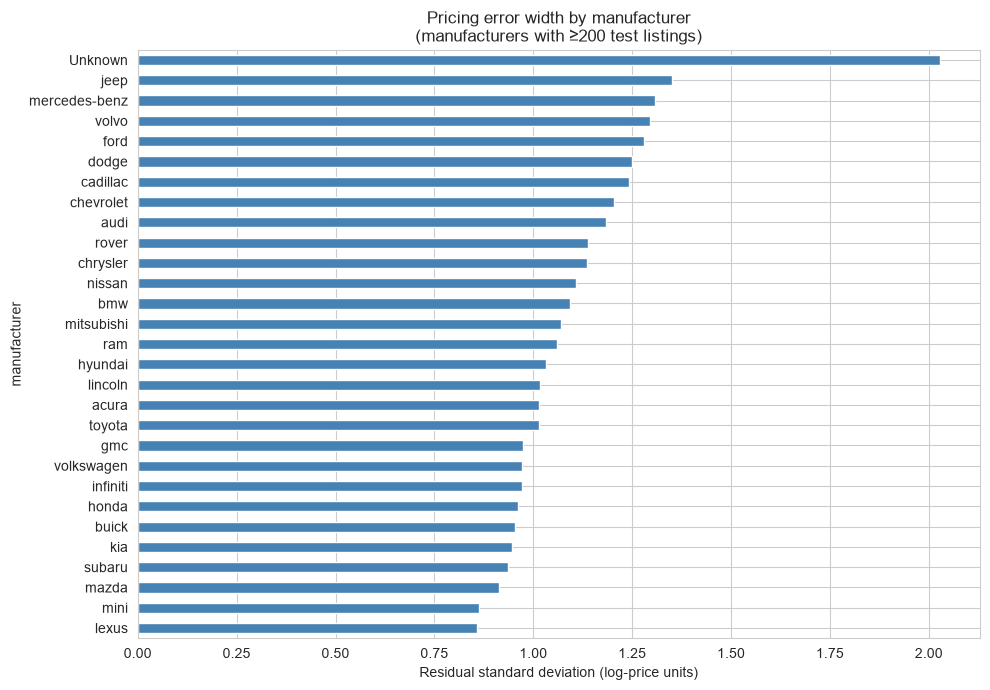

Widest pricing errors (top 8):
                mean    std     n
manufacturer                     
Unknown        0.405  2.028   573
jeep           0.094  1.350  1637
mercedes-benz -0.027  1.307  1299
volvo          0.042  1.295   245
ford           0.113  1.281  5905
dodge          0.054  1.249  1105
cadillac       0.203  1.242   585
chevrolet      0.069  1.204  4609


In [8]:
# Analyze residual standard deviation by manufacturer for manufacturers with ≥200 test listings
mfr_stats = (eval_set
             .groupby("manufacturer")["z_resid"]
             .agg(mean="mean", std="std", n="count")
             .query("n >= 200")
             .sort_values("std"))

# Plot residual standard deviation by manufacturer
fig, ax = plt.subplots(figsize=(10, 7))
mfr_stats["std"].plot(kind="barh", ax=ax, color="steelblue")
ax.set_xlabel("Residual standard deviation (log-price units)")
ax.set_title("Pricing error width by manufacturer\n(manufacturers with ≥200 test listings)")
plt.tight_layout()
plt.savefig(FIG_DIR / "residual_by_manufacturer.png", dpi=150)
plt.show()

print("Widest pricing errors (top 8):")
print(mfr_stats.tail(8).round(3).iloc[::-1])

We can see the widest residuals are not, as one might expect, concentrated among exotic or low-volume manufacturers. The highest standard deviation belongs to the `Unknown` manufacturer bucket (2.03), which is almost certainly a data-quality artifact - listings that failed to populate the manufacturer field likely also lack other attributes, giving the model less signal to work with. 

Beyond `Unknown`, the next widest are **jeep** and **mercedes-benz**. Because the model observes only `manufacturer` as a single category, it cannot distinguish within-brand trim, raising residual variance accordingly. 

### Year by odometer heatmap

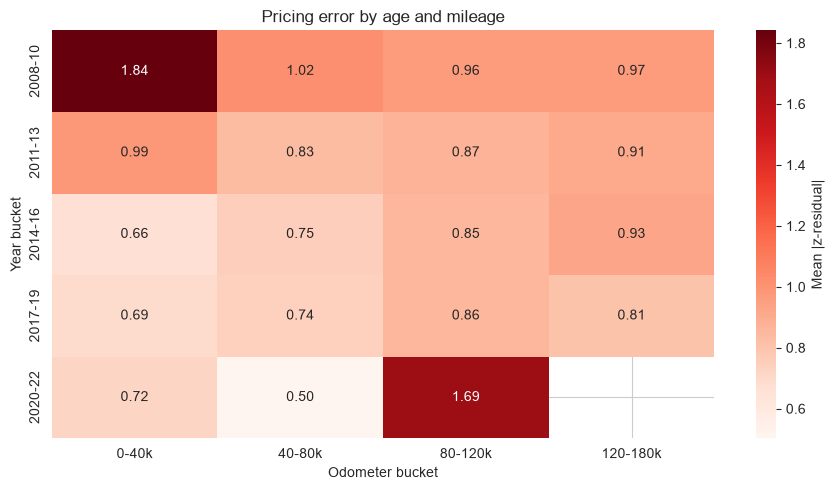

In [9]:
# Bin vehicles by year and odometer for residual analysis
eval_set["year_bin"] = pd.cut(eval_set["year"],
                              bins=[2007, 2010, 2013, 2016, 2019, 2022],
                              labels=["2008-10", "2011-13", "2014-16", "2017-19", "2020-22"])
eval_set["odo_bin"] = pd.cut(eval_set["odometer"],
                             bins=[0, 40_000, 80_000, 120_000, 180_000],
                             labels=["0-40k", "40-80k", "80-120k", "120-180k"])

# Create a pivot table of mean absolute z-residuals by year and odometer bins
pivot = (eval_set
         .groupby(["year_bin", "odo_bin"], observed=True)["z_resid"]
         .apply(lambda x: x.abs().mean())
         .unstack())

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(pivot, annot=True, fmt=".2f", cmap="Reds", ax=ax,
            cbar_kws={"label": "Mean |z-residual|"})
ax.set_xlabel("Odometer bucket"); ax.set_ylabel("Year bucket")
ax.set_title("Pricing error by age and mileage")
plt.tight_layout()
plt.savefig(FIG_DIR / "residual_heatmap.png", dpi=150)
plt.show()

The heatmap shows a clear monotonic pattern: residuals are narrowest in the newer, low-mileage cells and widen as both age and mileage increase. 

### Seller type and condition

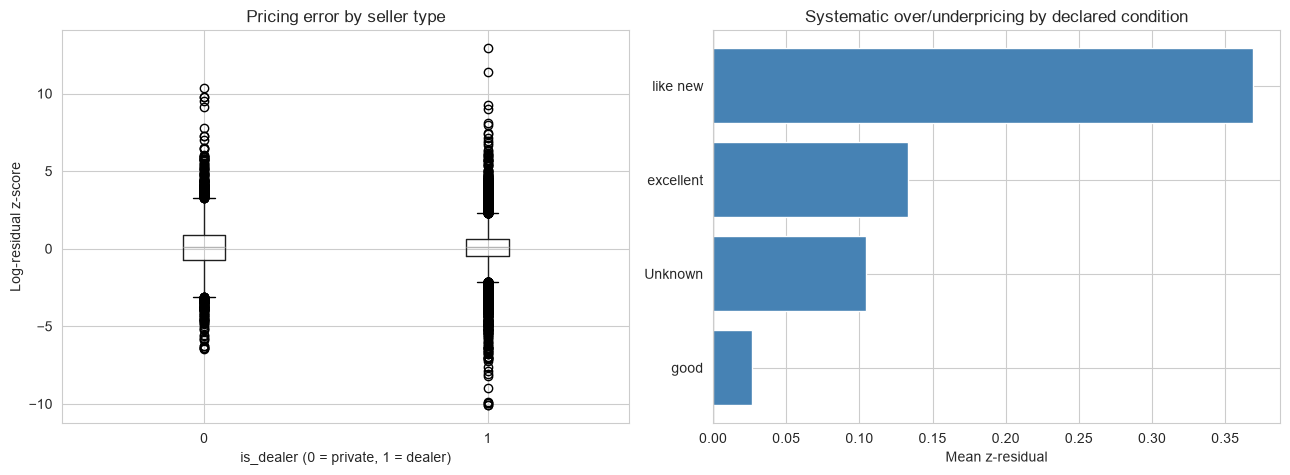

             count   mean    std     min    25%    50%    75%     max
is_dealer                                                            
0           5856.0  0.107  1.454  -6.463 -0.715  0.086  0.869  10.379
1          31780.0  0.102  1.093 -10.095 -0.463  0.101  0.642  12.913


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Compare residuals by seller type and vehicle condition
eval_set.boxplot(column="z_resid", by="is_dealer", ax=axes[0])
axes[0].set_xlabel("is_dealer (0 = private, 1 = dealer)")
axes[0].set_ylabel("Log-residual z-score")
axes[0].set_title("Pricing error by seller type")
plt.suptitle("")

# Compare residuals by vehicle condition for listings with sufficient data
cond_stats = (eval_set
              .groupby("condition")["z_resid"]
              .agg(mean="mean", n="count")
              .query("n >= 100")
              .sort_values("mean"))
axes[1].barh(cond_stats.index, cond_stats["mean"], color="steelblue")
axes[1].axvline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("Mean z-residual")
axes[1].set_title("Systematic over/underpricing by declared condition")

plt.tight_layout()
plt.savefig(FIG_DIR / "residual_segments.png", dpi=150)
plt.show()

print(eval_set.groupby("is_dealer")["z_resid"].describe().round(3))

Considering seller type, we see dealer listings have a residual standard deviation of 1.09 while private-party listings have 1.45, a 33% wider spread. This is expected, as dealers post prices determined by professional pricing systems, while private sellers price from less formal systems. For the prediction band contruction, it would make sense to have per-segment quantiles here: the private-party band would be noticeably wider than the dealer band. 

Furthermore, listings with unknown declared condition show systematically *negative* mean residuals - they price below what their other attributes would predict. This is not really surprising. A private seller or budget-oriented dealer who omits the condition field may be signalling something. 

## 4. Pricing Band
A dealership cannot act on "predicted log-price = 9.85." Dealerships need a pricing *range*. Here, we construct an 80% prediction band non-parametrically from the training residual distribution: 

    lo_price = exp(pred_log + q10(train_residuals))
    hi_price = exp(pred_log + q90(train_residuals))

Listings whose actual price falls outside the band are flagged under the mispricing definition from Section 2 (with the caveat that per-segment bands would be tighter still, if a dealership has enough listings in any one segment to justify segment-specific quantiles; we will assume not). 

In [11]:
#Develop prediction intervals based on training residual quantiles
# Use the 10th and 90th percentiles of the training residuals to define the lower and upper bounds of the prediction interval
q10, q50, q90 = np.percentile(train_resid, [10, 50, 90])
print(f"Training residual quantiles: q10={q10:.3f}   q50={q50:.3f}   q90={q90:.3f}")

eval_set["lo_price"] = np.exp(np.log(eval_set["pred_price"]) + q10) # Lower bound of prediction interval
eval_set["hi_price"] = np.exp(np.log(eval_set["pred_price"]) + q90) # Upper bound of prediction interval

inside = (eval_set["actual_price"].between(eval_set["lo_price"], eval_set["hi_price"]))
print(f"Coverage of 80% band on trimmed test: {inside.mean():.1%}") # Proportion of actual prices within the prediction interval

Training residual quantiles: q10=-0.201   q50=0.004   q90=0.212
Coverage of 80% band on trimmed test: 69.5%


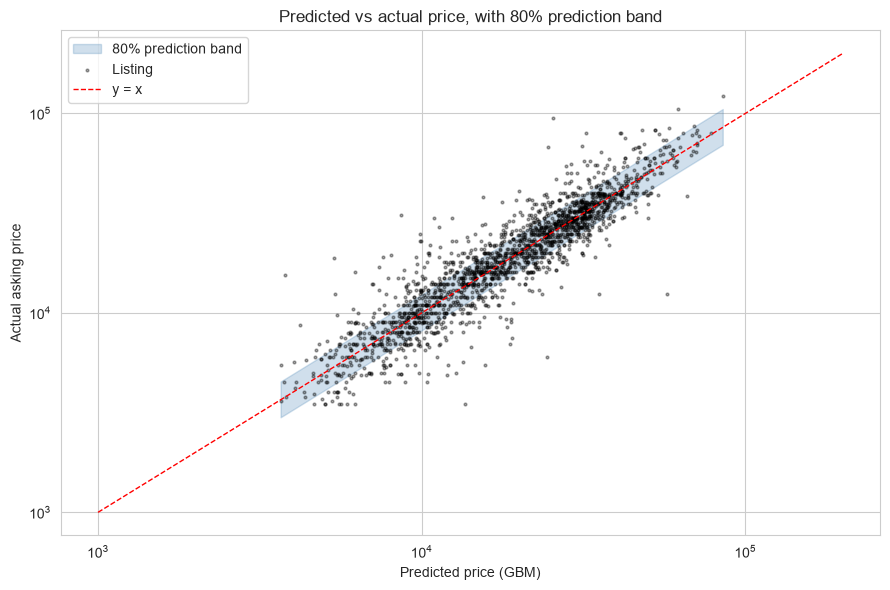

In [12]:
sample = eval_set.sample(2000, random_state=42).sort_values("pred_price") # Take a random sample of 2000 listings for plotting

#Plot predicted vs actual prices with 80% prediction band
fig, ax = plt.subplots(figsize=(9, 6))
ax.fill_between(sample["pred_price"], sample["lo_price"], sample["hi_price"],
                alpha=0.25, color="steelblue", label="80% prediction band")
ax.scatter(sample["pred_price"], sample["actual_price"], s=4, alpha=0.35,
           color="black", label="Listing")
ax.plot([1e3, 2e5], [1e3, 2e5], "r--", linewidth=1, label="y = x")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Predicted price (GBM)"); ax.set_ylabel("Actual asking price")
ax.set_title("Predicted vs actual price, with 80% prediction band")
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(FIG_DIR / "pricing_band.png", dpi=150)
plt.show()

### Interpretation
The 80% pricing band constructed from training residual quantiles covers only 69.5% of the trimmed test set, well below the nominal 80%. This is a significant under-coverage problem, and it has a specific cause: the **test residuals are approximately 50% wider than the training residuals.** Training residual standard deviation is 0.217; test RMSE is 0.326 (train RMSE 0.217, val 0.299, test 0.326). A band calibrated at the 10th/90th percentiles of a 0.217 wide residual distribution is simply too narrow to cover 80% of a 0.326 wide residual distribution. 

This seems like an expected consequence of the time-ordered split. The test set consists of the *latest* 15% of listings by `posting_date`, and the model was trained on the *earliest* 70%. Over that gap, the price distribution shifted: later listings price higher on average, and the residual variance also grew. 

Therefore, we can: 
1. **Calibrate on validation residuals instead of training residuals**. The validation set sits between train and test chronologically, so its residuals are closer in distribution to the test set. 
2. Alternatively, we could just report the shortfall as a limitation. 

## 5. Depreciation Schedule
The SHAP analysis in `03_modeling.ipynb` identified `year` and `odometer` as the two dominant predictors. This section translates that into dollars, holding other features fixed at a representative configuration (median for numeric, mode for categorical) and sweeping one variable at a time. 

In [13]:
# Create a representative listing using median for numeric features and mode for categorical features
rep = {**{c: train[c].median() for c in NUMERIC},
       **{c: train[c].mode().iloc[0] for c in CATEGORICAL},
       "is_dealer": 1}

print("Representative listing:")
for k, v in rep.items():
    print(f"  {k:20s} {v}")

Representative listing:
  year                 2015.0
  odometer             69079.5
  dist_to_major_metro  129.1585599008373
  manufacturer         ford
  condition            Unknown
  cylinders            Unknown
  fuel                 gas
  transmission         automatic
  drive                4wd
  size                 Unknown
  type                 sedan
  paint_color          Unknown
  census_region        South
  is_dealer            1


### Year sweep

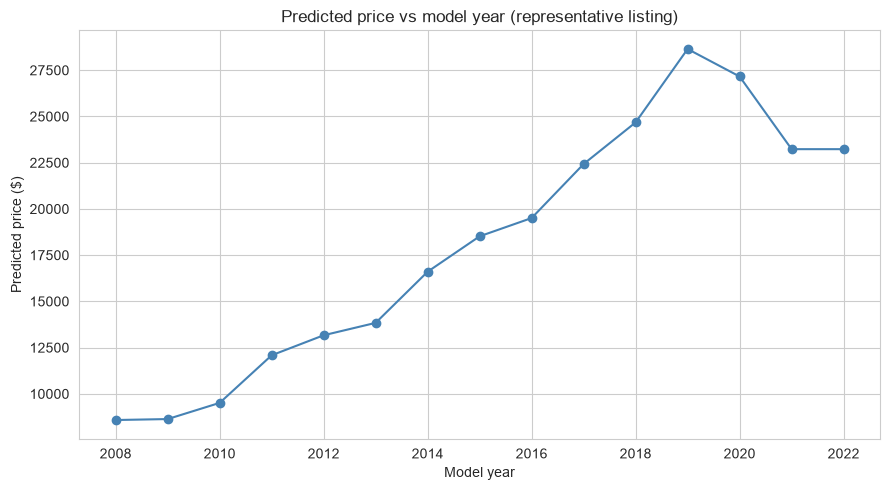

Average price drop per year of age: $1,046


In [18]:
years = np.arange(2008, 2023) # Range of model years to consider
year_frame = pd.DataFrame([{**rep, "year": y} for y in years])[PREDICTORS] # Create a DataFrame for each model year with the representative listing
year_pred = np.exp(gbm_final.predict(year_frame)) # Predicted prices for each model year

#Plot predicted price vs model year for the representative listing
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(years, year_pred, marker="o", color="steelblue")
ax.set_xlabel("Model year"); ax.set_ylabel("Predicted price ($)")
ax.set_title("Predicted price vs model year (representative listing)")
plt.tight_layout()
plt.savefig(FIG_DIR / "depreciation_year.png", dpi=150)
plt.show()

print(f"Average price drop per year of age: ${np.diff(year_pred).mean():,.0f}")

### Odometer sweep

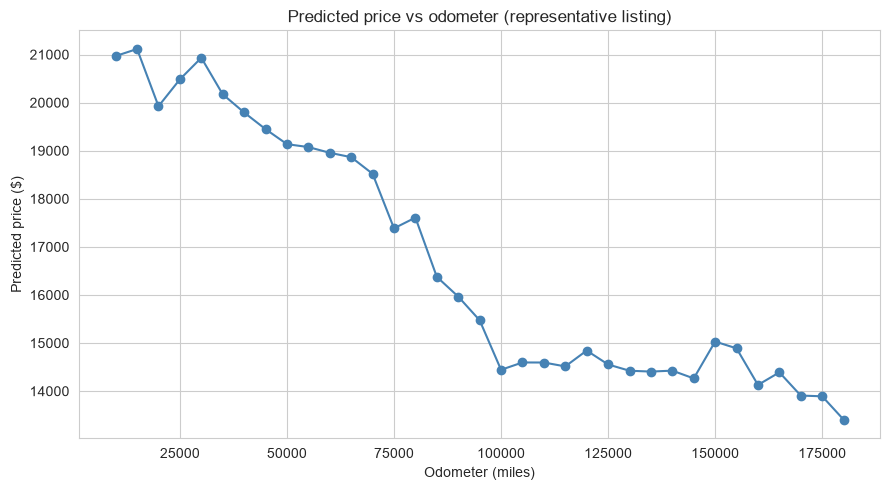

Average price drop per 10,000 miles: $445


In [15]:
odos = np.arange(10_000, 181_000, 5_000) # Range of odometer readings to consider
# Create a DataFrame for each odometer reading with the representative listing
odo_frame = pd.DataFrame([{**rep, "odometer": o} for o in odos])[PREDICTORS]
odo_pred = np.exp(gbm_final.predict(odo_frame)) # Predicted prices for each odometer reading

#Plot predicted price vs odometer for the representative listing
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(odos, odo_pred, marker="o", color="steelblue")
ax.set_xlabel("Odometer (miles)"); ax.set_ylabel("Predicted price ($)")
ax.set_title("Predicted price vs odometer (representative listing)")
plt.tight_layout()
plt.savefig(FIG_DIR / "depreciation_odometer.png", dpi=150)
plt.show()

per_10k = -np.diff(odo_pred).mean() / ((odos[1] - odos[0]) / 10_000) #Compute average price drop per 10,000 miles
print(f"Average price drop per 10,000 miles: ${per_10k:,.0f}")

## 6. Worked Demo

Here, we will construct four hypothetical listings to run through the model, chosen to cover the scenarios a dealership actually encounters: 

- A **volume mover** (late-model pickup with typical miles)
- The **same truck with high mileage**
- A **luxury sedan** (does the model treat a BMW like a Toyota Camry?)
- A **late-model economy sedan** (a safer bet)
- **My own truck I am trying to sell** (basically salvage, but with a clean title. Not great for this model.)

In [17]:
base = lambda **kw: {**rep, **kw} # Function to create a listing based on the representative listing with overridden values
hypotheticals = pd.DataFrame([
    base(year=2018, odometer=60_000,  manufacturer="ford",   type="pickup",
         cylinders="6 cylinders", drive="4wd", fuel="gas", transmission="automatic"),
    base(year=2018, odometer=120_000, manufacturer="ford",   type="pickup",
         cylinders="6 cylinders", drive="4wd", fuel="gas", transmission="automatic"),
    base(year=2015, odometer=90_000,  manufacturer="bmw",    type="sedan",
         cylinders="4 cylinders", drive="rwd", fuel="gas", transmission="automatic"),
    base(year=2020, odometer=20_000,  manufacturer="toyota", type="sedan",
         cylinders="4 cylinders", drive="fwd", fuel="gas", transmission="automatic"),
    base(year=2008, odometer=60_000,  manufacturer="chevrolet", type="pickup", # My truck, I expect it to be overpriced. 
            cylinders="8 cylinders", drive="rwd", fuel="gas", transmission="automatic"),
])

pred_log = gbm_final.predict(hypotheticals[PREDICTORS]) # Predicted log prices for the hypothetical listings
hypotheticals["predicted"] = np.exp(pred_log) # Convert log prices to actual prices
hypotheticals["low"]       = np.exp(pred_log + q10) # Lower bound of the predicted price interval
hypotheticals["high"]      = np.exp(pred_log + q90) # Upper bound of the predicted price interval

display = ["year", "manufacturer", "type", "odometer",
           "predicted", "low", "high"]
print(hypotheticals[display].round(0).to_string(index=False))

 year manufacturer   type  odometer  predicted     low    high
 2018         ford pickup     60000    41101.0 33603.0 50796.0
 2018         ford pickup    120000    34718.0 28384.0 42907.0
 2015          bmw  sedan     90000    15362.0 12560.0 18986.0
 2020       toyota  sedan     20000    22337.0 18262.0 27606.0
 2008    chevrolet pickup     60000    22573.0 18455.0 27898.0


## 7. Summary
### Business takeaways
The analysis closes the four statistical goals from the proposal, and produces a coherent set of findings that can drive the README and final presentation. 

**Model Performance:** A gradient-boosted model trained on ~254,000 cleaned listings achives **test $R^2$ = 0.79** on `log_price` - a 17% reduction in RMSE relative to the OLS baseline (0.326 vs. 0.396), and roughly $2,000 - $3,000 less error per listing at median prices. 

The OLS diagnostics in `03_modeling.ipynb` showed severe functional-form misspecification and heteroskedasicity, meaning the linear-in-parameters model cannot represent the true relationship between features and log-price. The GBM captures both nonlinearity and the interaction structure that the OLS model misses. 

**What drives price:** The SHAP analysis identified `year` and `odometer` as the dominant predictors, contributing roughly 2x the next-best feature each. This is a core business finding: **the two attributes any dealership can observe for free explain most of the predictable variation in posted price.**

**Depreciation in dollars:** Translating the SHAP ranking into dollar terms, the model implies a **$1,046 average drop per year of age** and a **$455 average drop per 10,000 miles** on the median representative listing. Both relationships are slightly concave (steeper at younger, lower-mileage points), consistent with an expected standard depreciation pattern. 

**Dealer vs. private:** Dealer listings post approximately 12.6% higher than comparable private-party listings, and the dealer-only sensitivity model in `03_modeling.ipynb` confirmed that this premium does not confound the other coefficients. 

**Mispricing flag:** With a trimmed price range ($3,000 - $150,000) and a log-residual z-score, the flag identifies roughly 3,800 mispriced test listings while excluding data-entry artifacts that a percentage-gap threshold would have caught. The 3,258 listings flagged by both the old and new rules are the highest-confidence candidates for pricing anomalies. 

**Pricing band:** The 80% prediction band, constructed from training residual quantiles, covers 69.5% of the trimmed test set - below nominal, reflecting the time-drift between the training and test periods. This is a real generalization gap that a deployment model would face. 

### Limitations 
Several limitations should be stated, and have been documented throughout the project. 

**Response is asking price, not transaction price**. The model predicts what sellers *post*, not what they ultimately *accept*. This means coefficients describe listing behavior, not market-clearing behavior, and a dealership using the model for acquisition pricing should not treat the predicted price as a clearing price. 

**Mechanical condition is unobserved.** The model sees `condition` (self-reported), `title_status`, `year`, and `odometer`, but it cannot see whether the engine runs, whether the transmission slips, or whether there is frame damage. Listings whose prices reflect undisclosed mechanical problems will appear as residual anomalies rather than being modeled corrrectly. This is why my "basically salvage" 2008 Chevrolet pickup in the worked demo predicts at $22,573 despite my knowledge that the frame is rotted, and worth roughly $1,000. 

**Dealer-dominated sample:** After filtering 89.7% of listings are dealer postings. The model is therefore best interpreted as a *dealer-inventory pricing model with a private-party comparison subsample*, and the coefficients are weighted toward dealer pricing behavior. The private-party residual spread (1.45 vs. 1.09) suggests that a separate private-party model would produce meaningfully different point predictions and bands. 

**Time drift:** Test residuals are 50% wider than training residuals, and the 80% band achieves only 69.5% coverage on the test set. This reflects real distributional drift between training and test periods. An actual deployed model would need to be recalibrated on a rolling window rather than fit once and frozen. 

**Iteration budget:** The GBM used its full `max_iter` budget (2,000 iterations) without triggering early stopping, indicating that additional capacity could yield further small performance improvements. 

**Coordinate exclusions:** Approximately 1.1% of the modeling subset was dropped for implausible `lat`/`long` coordinates. These dropped listings were not a random sample - they are geographically bad records - and the dropped population may differ systematically from the retained one. 

**Per-segment calibration:** The section 4 band is uniform across all listings, but Section 3 showed that residuals vary substantially by manufacturer, age, mileage, and seller type. A production system would benefit from per-segment calibration. 